<a href="https://colab.research.google.com/github/eodanyelsn/focus-tracker/blob/main/focus_tracker.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

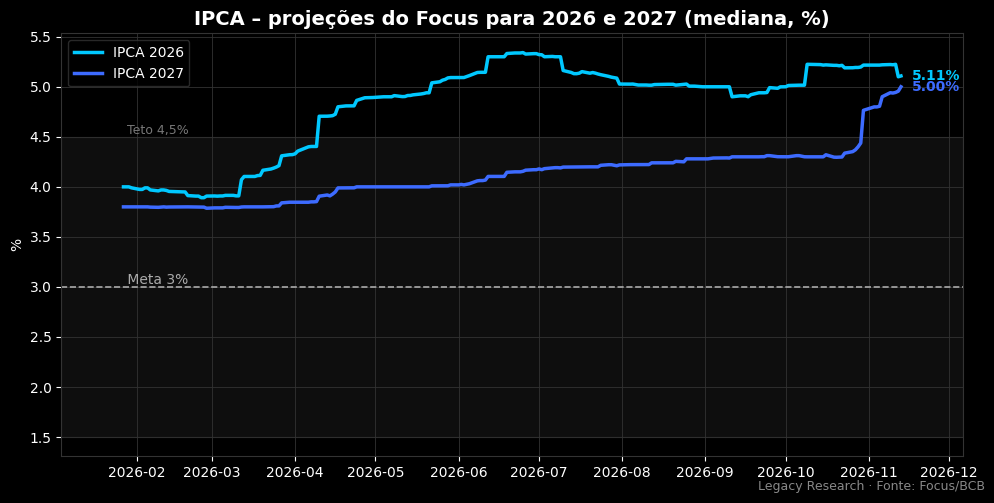

In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

# 1. Pedir os dados ao Banco Central (agora 2026 e 2027)
url = (
    "https://olinda.bcb.gov.br/olinda/servico/Expectativas/versao/v1/odata/ExpectativasMercadoAnuais"
    "?$filter=Indicador%20eq%20'IPCA'%20and%20(DataReferencia%20eq%20'2026'%20or%20DataReferencia%20eq%20'2027')%20and%20baseCalculo%20eq%200"
    "&$orderby=Data%20desc"
    "&$top=400"
    "&$format=json"
    "&$select=Data,DataReferencia,Mediana"
)
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36"
}
resposta = requests.get(url, headers=headers)
resposta.raise_for_status()

# 2. Montar a tabela
df = pd.DataFrame(resposta.json()["value"])
df["Data"] = pd.to_datetime(df["Data"])
df = df.sort_values("Data")

# 3. Gráfico nas cores da Legacy
FUNDO = "#000000"
TEXTO = "#FFFFFF"
GRADE = "#333333"
CORES = {"2026": "#00C8FF", "2027": "#3D6BFF"}   # azul fluorescente e azul royal

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(FUNDO)
ax.set_facecolor(FUNDO)

# Meta de inflação e intervalo de tolerância
ax.axhspan(1.5, 4.5, color="#FFFFFF", alpha=0.06)
ax.axhline(3.0, color="#AAAAAA", linestyle="--", linewidth=1.2)
ax.text(df["Data"].iloc[0], 3.0, " Meta 3%", color="#AAAAAA", va="bottom", fontsize=10)
ax.text(df["Data"].iloc[0], 4.5, " Teto 4,5%", color="#777777", va="bottom", fontsize=9)

# Uma linha para cada ano
for ano, cor in CORES.items():
    dados = df[df["DataReferencia"] == ano]
    ax.plot(dados["Data"], dados["Mediana"], color=cor, linewidth=2.5, label=f"IPCA {ano}")
    ultimo = dados.iloc[-1]
    ax.annotate(f"{ultimo['Mediana']:.2f}%", (ultimo["Data"], ultimo["Mediana"]),
                xytext=(8, 0), textcoords="offset points",
                color=cor, fontweight="bold", va="center")

ax.set_title("IPCA – projeções do Focus para 2026 e 2027 (mediana, %)", color=TEXTO, fontsize=14, fontweight="bold")
ax.set_ylabel("%", color=TEXTO)
ax.tick_params(colors=TEXTO)
for borda in ax.spines.values():
    borda.set_color(GRADE)
ax.grid(color=GRADE, linewidth=0.6)
ax.margins(x=0.08)
ax.legend(facecolor=FUNDO, edgecolor=GRADE, labelcolor=TEXTO, loc="upper left")

fig.text(0.99, 0.01, "Legacy Research · Fonte: Focus/BCB", color="#888888", ha="right", fontsize=9)

plt.tight_layout()
plt.savefig("ipca_focus_2026_2027.png", dpi=200, facecolor=FUNDO)
plt.show()
